In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# --- Custom imports ---
from Helpers import *   # Contains utility functions for data processing and plotting

# Configure matplotlib for consistent plots
plt.style.use("seaborn-v0_8-whitegrid")

In [3]:
def load_data(file_path):
    with open(file_path, 'rb') as file:
        return pickle.load(file)

In [4]:
# --- Load data files ---
ROOT_PATH = "/data/sukhanna/MPP/"
PARENT_PATH = ROOT_PATH +"ver_2/ver_2A/new_MAT/"
DATA_PATH = PARENT_PATH +"final_df.parquet"

final_df = pd.read_parquet(DATA_PATH)

id_to_seq = load_data(PARENT_PATH + "sequence_dict.pkl")

refSeq = getReference(ROOT_PATH + 'cov_reference.fa')

# ver = 'Nov_29_21'
ver = 'Jan_4_24'

pyro_df = pd.read_pickle(ROOT_PATH + f'pyro_ver/{ver}/PyroSpike.pkl')

eve_df = pd.read_csv(ROOT_PATH + 'EVEscape/EVEscore_Wuhan_A')

In [5]:
# --- Define cutoff date ---
#cutoff_date = "2022-07-01"
cutoff_date = "2023-07-01"

d = 30

# --- Split dataframe into circulating and future segments ---
current_df, future_df = split_circulating_and_future(
    final_df,
    cutoff_date_str=cutoff_date,
    left_buffer_days=4,
    right_buffer_days=4,
    circulation_months=None,
    circulation_days=d,
    future_months=12,
    future_days=None
)

# --- Define windows for slicing future data ---
disjoint_windows = ['3M_1', '3M_2', '3M_3', '3M_4']

# --- Perform slicing ---
# cumulative_slices = slice_by_cumulative_windows(future_df, cumulative_windows)
disjoint_slices = slice_by_disjoint_windows(future_df, disjoint_windows)

# --- Combine slices into one dictionary ---
future_slices = disjoint_slices

# --- Summary output ---
# print(f"Cumulative slices: {list(cumulative_slices.keys())}")
print(f"Disjoint slices: {list(disjoint_slices.keys())}")
print(f"Total future slices stored: {len(future_slices)}")

Disjoint slices: ['3M_1', '3M_2', '3M_3', '3M_4']
Total future slices stored: 4


In [6]:
# --- Group by sequence ID and count tips ---
current_seq_df = (
    current_df.groupby('Sequence_ID')
    .size()
    .reset_index(name='Tip_Count')
    .sort_values(by='Tip_Count', ascending=False)
    .reset_index(drop=True)
)

future_seq_dfs = {
    k: (
        v.groupby('Sequence_ID')
        .size()
        .reset_index(name='Tip_Count')
        .sort_values(by='Tip_Count', ascending=False)
        .reset_index(drop=True)
    )
    for k, v in future_slices.items()
}

print("Total Tips:", len(current_df))
print("Total Spikes:", len(current_seq_df))

Total Tips: 72768
Total Spikes: 9794


In [26]:
############NEW
def save_dict_to_fasta(sequence_dict, output_filename):
    """
    Writes a dictionary of {ID: Sequence} to a FASTA file.
    """
    with open(output_filename, 'w') as f:
        for seq_id, sequence in sequence_dict.items():
            # Write the header line starting with '>'
            f.write(f">{seq_id}\n")
            # Write the sequence line
            f.write(f"{sequence}\n")

# Save them into separate FASTA files 
current_sequences_dict = {
    seq_id: id_to_seq[seq_id] 
    for seq_id in current_seq_df['Sequence_ID'] 
    if seq_id in id_to_seq # This prevents KeyErrors if an ID is missing
}
save_dict_to_fasta(current_sequences_dict, f"current_sequences_{cutoff_date}.fa")

In [7]:
# -- Process Sequence Weights --- 
current_seq_df["Weight"] = current_seq_df["Tip_Count"] / current_seq_df["Tip_Count"].sum()
current_seq_df["Weight_pct"] = current_seq_df["Weight"] * 100
# print("Sum of weights:", current_seq_df["Weight"].sum())

for interval, df in future_seq_dfs.items():
    # Calculate the normalized weight (sums to 1)
    df["Weight"] = df["Tip_Count"] / df["Tip_Count"].sum()
    
    # Calculate the weight as a percentage (sums to 100)
    df["Weight_pct"] = df["Weight"] * 100

In [8]:
# --- Load Pairwise Distance Matrix ---
dist_df = pd.read_parquet(f"/data/sukhanna/MPP/ver_2/ver_2A/new_MAT/Disjoint_30D/{cutoff_date}/pairwise.parquet", engine="pyarrow")

Preprocess Weights and Distance

In [9]:
def preprocess_for_weighted_pam_fast(current_seq_df: pd.DataFrame, dist_df: pd.DataFrame):
    """
    Fast vectorized preprocessing for weighted PAM.

    Args:
        current_seq_df: pd.DataFrame with columns ['Sequence_ID', 'Weight']
        dist_df: pd.DataFrame with columns ['Seq_1', 'Seq_2', 'Distance']

    Returns:
        dist_matrix: np.ndarray of shape (N, N), symmetric distance matrix
        weights: np.ndarray of shape (N,), aligned to matrix
        id2idx: dict mapping Sequence_ID -> index
        idx2id: dict mapping index -> Sequence_ID
    """
    # Index sequences
    sequence_ids = current_seq_df['Sequence_ID'].tolist()
    id2idx = {sid: i for i, sid in enumerate(sequence_ids)}
    idx2id = {i: sid for sid, i in id2idx.items()}
    n = len(sequence_ids)

    # Vectorized index lookup
    i_indices = dist_df['Seq_1'].map(id2idx).to_numpy()
    j_indices = dist_df['Seq_2'].map(id2idx).to_numpy()
    distances = dist_df['Distance'].to_numpy(dtype=np.float32)

    # Fill symmetric distance matrix
    dist_matrix = np.zeros((n, n), dtype=np.float32)
    dist_matrix[i_indices, j_indices] = distances
    dist_matrix[j_indices, i_indices] = distances

    # Prepare weights vector
    weights_series = current_seq_df.set_index('Sequence_ID')['Weight']
    weights = np.array([weights_series[idx2id[i]] for i in range(n)], dtype=np.float32)

    # Create a fast dictionary lookup: {Sequence_ID: Score}
    scores_file = f"current_sequences_scores_{cutoff_date}.csv"
    if os.path.exists(scores_file):
        scores_df = pd.read_csv(scores_file)
        score_dict = scores_df.set_index('name')['neutralization_retained'].to_dict()
    
        # Build the aligned array using your existing idx2id mapping and n
        # If a sequence is missing from the CSV, it defaults to 1.0
        nr_scores = np.array([score_dict.get(idx2id[i], 1.0) for i in range(n)], dtype=np.float32)
        print(f"Loaded NR scores for {len(score_dict)} sequences.")
    else:
        nr_scores = None
        print(f"File {scores_file} not found. Running standard unpenalized PAM.")

    return dist_matrix, weights, id2idx, idx2id, nr_scores

In [10]:
dist_matrix, weights, id2idx, idx2id, nr_scores = preprocess_for_weighted_pam_fast(current_seq_df, dist_df)

Loaded NR scores for 9794 sequences.


PAM Code - Driving Function of Medoid Selection

In [11]:
def weighted_pam(dist_matrix, weights, k, nr_scores=None, alpha=0.0, max_iter=100, verbose=False):
    """
    Weighted PAM clustering with greedy BUILD + SWAP.
    Optionally incorporates an immune-evasion penalty: 
    Modified_Dist = Dist * (1 + alpha * NR_score)

    Args:
        dist_matrix: np.ndarray, shape (N, N), symmetric distance matrix
        weights: np.ndarray, shape (N,), positive weights
        k: int, number of medoids
        nr_scores: np.ndarray, shape (N,), optional neutrailization_retained scores
        alpha: float, weight for nr_scores
        max_iter: int, max SWAP iterations
        verbose: bool, if True prints progress

    Returns:
        medoids: list of medoid indices
        labels: np.ndarray, assigned medoid index for each point
        final_cost: float, weighted clustering cost
    """
    n = dist_matrix.shape[0]
    if k <= 0 or k > n:
        raise ValueError("k must be between 1 and N")

    # --- NEW: Set up the modifiers based on nr_scores ---
    if nr_scores is not None and alpha > 0.0:
        modifiers = 1.0 + (alpha * nr_scores)
    else:
        modifiers = np.ones(n, dtype=np.float32)

    # --- BUILD phase ---
    remaining = set(range(n))
    medoids = []

    # First medoid: minimize sum_i f_i * d(i, candidate)
    total_weighted_dists = (dist_matrix * weights.reshape(1, -1)).sum(axis=1) * modifiers
    first = int(np.argmin(total_weighted_dists))
    medoids.append(first)
    remaining.remove(first)

    # dist1 = distance to nearest medoid
    def assign_to_medoids(dist_matrix, medoids):
        d_to_m = dist_matrix[:, medoids] * modifiers[medoids]
        nearest_idx = np.argmin(d_to_m, axis=1)
        dist1 = d_to_m[np.arange(n), nearest_idx]
        d_to_m_tmp = d_to_m.copy()
        d_to_m_tmp[np.arange(n), nearest_idx] = np.inf
        dist2 = d_to_m_tmp[np.arange(n), np.argmin(d_to_m_tmp, axis=1)]
        nearest_medoid = np.array(medoids)[nearest_idx]
        return nearest_idx, nearest_medoid, dist1, dist2

    _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    for _ in range(1, k):
        best_candidate = None
        best_cost = np.inf
        for c in remaining:
            new_dist = np.minimum(dist1, dist_matrix[:, c] * modifiers[c])
            cost_if_added = float(np.dot(weights, new_dist))
            if cost_if_added < best_cost:
                best_cost = cost_if_added
                best_candidate = c
        medoids.append(int(best_candidate))
        remaining.remove(best_candidate)
        _, _, dist1, _ = assign_to_medoids(dist_matrix, medoids)

    if verbose:
        print(f"[BUILD] Initial medoids: {medoids}")

    # --- SWAP phase ---
    it = 0
    improved = True
    history = []

    while improved and it < max_iter:
        improved = False
        best_delta = 0
        best_swap = None
        medoids_set = set(medoids)

        nearest_idx, nearest_medoid, dist1, dist2 = assign_to_medoids(dist_matrix, medoids)

        for m_pos, m in enumerate(medoids):
            for h in range(n):
                if h in medoids_set:
                    continue
                d_ih = dist_matrix[:, h] * modifiers[h]
                mask_better = d_ih < dist1
                delta_better = ((d_ih - dist1) * weights)[mask_better].sum()
                mask_owned_by_m = (nearest_medoid == m)
                mask_case2 = mask_owned_by_m & (~mask_better)
                new_dist_case2 = np.minimum(dist2, d_ih)
                delta_case2 = ((new_dist_case2 - dist1) * weights)[mask_case2].sum()
                delta = delta_better + delta_case2
                if delta < best_delta:
                    best_delta = delta
                    best_swap = (m_pos, h)

        if best_swap and best_delta < -1e-12:
            m_pos, h = best_swap
            medoids[m_pos] = h
            improved = True
        else:
            break
        it += 1

    # final assignment
    _, nearest_medoid, dist1, _ = assign_to_medoids(dist_matrix, medoids)
    final_cost = float(np.dot(weights, dist1))
    labels = nearest_medoid.copy()

    return medoids, labels, final_cost

In [25]:
# --- Run weighted PAM for K = 1 to 4 ---
alpha = 1.0
pam_results = {}

for k in range(1, 5):  # K = 1 to 4
    print(f"\nRunning weighted PAM for K = {k}")
    
    medoids, labels, cost = weighted_pam(
        dist_matrix,
        weights,
        k=k,
        nr_scores=nr_scores,
        alpha=alpha,
        max_iter=100,
        verbose=False
    )
    
    # Map indices back to sequence IDs
    medoid_ids = [idx2id[i] for i in medoids]
    label_ids = [idx2id[i] for i in labels]
    
    # Store results in dict
    pam_results[k] = {
        'medoids': medoid_ids,
        'labels': label_ids,
        'cost': cost
    }


Running weighted PAM for K = 1

Running weighted PAM for K = 2

Running weighted PAM for K = 3

Running weighted PAM for K = 4


In [17]:
################CHECK-1
def evaluate_cluster_reassignment(target_medoid_id, alt_medoid_id, k, pam_results, dist_matrix, weights, id2idx, idx2id):
    """
    Evaluates the cost of reassigning an entire cluster from its current medoid 
    to a user-provided alternative medoid.
    """
    # 1. Retrieve the labels for the specific K run
    if k not in pam_results:
        raise ValueError(f"Results for K={k} not found in pam_results.")
    
    labels_list = pam_results[k]['labels']
    labels_array = np.array(labels_list)
    
    # 2. Find all sequences assigned to the target medoid
    # mask is a boolean array: True for sequences in the target cluster
    cluster_mask = (labels_array == target_medoid_id)
    cluster_indices = np.where(cluster_mask)[0]
    num_sequences = len(cluster_indices)
    
    if num_sequences == 0:
        print(f"Warning: No sequences are currently assigned to {target_medoid_id}.")
        return

    # 3. Get matrix coordinates for the medoids
    target_idx = id2idx[target_medoid_id]
    
    if alt_medoid_id not in id2idx:
         raise ValueError(f"Alternative medoid '{alt_medoid_id}' not found in the dataset.")
    alt_idx = id2idx[alt_medoid_id]

    # 4. Extract the distances and weights for this specific cluster
    cluster_weights = weights[cluster_indices]
    
    # Distances to the current target medoid
    dists_to_target = dist_matrix[cluster_indices, target_idx]
    
    # Distances to the alternative medoid
    dists_to_alt = dist_matrix[cluster_indices, alt_idx]

    # 5. Calculate the metrics
    target_weighted_sum = np.sum(dists_to_target * cluster_weights)
    target_raw_sum = np.sum(dists_to_target)
    target_mean = np.mean(dists_to_target)
    target_median = np.median(dists_to_target)
    target_variance = np.var(dists_to_target)

    alt_weighted_sum = np.sum(dists_to_alt * cluster_weights)
    alt_raw_sum = np.sum(dists_to_alt)
    alt_mean = np.mean(dists_to_alt)
    alt_median = np.median(dists_to_alt)
    alt_variance = np.var(dists_to_alt)

    # 6. Print the results
    print(f"{'='*50}")
    print(f"CLUSTER ANALYSIS: {target_medoid_id} -> {alt_medoid_id}")
    print(f"{'='*50}")
    print(f"Total Unique Sequences in Cluster : {num_sequences}")
    print(f"Total Sequence Weight (Tip Count) : {np.sum(cluster_weights)*100:.2f}%\n")
    
    print(f"CURRENT ASSIGNMENT (Center: {target_medoid_id})")
    print(f"  - Weighted Distance Sum: {target_weighted_sum:.4f}")
    print(f"  - Raw Distance Sum     : {target_raw_sum:.4f}")
    print(f"Mean: {target_mean}, Median: {target_median}, Variance: {target_variance}\n")
    
    print(f"HYPOTHETICAL REASSIGNMENT (Center: {alt_medoid_id})")
    print(f"  - Weighted Distance Sum: {alt_weighted_sum:.4f}")
    print(f"  - Raw Distance Sum     : {alt_raw_sum:.4f}")
    print(f"Mean: {alt_mean}, Median: {alt_median}, Variance: {alt_variance}\n")
    
    delta = alt_weighted_sum - target_weighted_sum
    print(f"WEIGHTED PENALTY FOR SWAP: {delta:+.4f}")
    print(f"{'='*50}")

# --- Example Execution ---
# You can replace these strings with the actual IDs from your dataset
target_medoid = "S_387141" 
alternative_medoid = "S_163522"                   # Replace with your desired alternative

evaluate_cluster_reassignment(
    target_medoid_id=target_medoid,
    alt_medoid_id=alternative_medoid,
    k=2,
    pam_results=pam_results,
    dist_matrix=dist_matrix,
    weights=weights,
    id2idx=id2idx,
    idx2id=idx2id
)

CLUSTER ANALYSIS: S_387141 -> S_163522
Total Unique Sequences in Cluster : 1575
Total Sequence Weight (Tip Count) : 7.80%

CURRENT ASSIGNMENT (Center: S_387141)
  - Weighted Distance Sum: 0.6870
  - Raw Distance Sum     : 14086.0000
Mean: 8.94349193572998, Median: 8.0, Variance: 17.262203216552734

HYPOTHETICAL REASSIGNMENT (Center: S_163522)
  - Weighted Distance Sum: 1.4837
  - Raw Distance Sum     : 30057.0000
Mean: 19.08380889892578, Median: 18.0, Variance: 10.991071701049805

WEIGHTED PENALTY FOR SWAP: +0.7967


In [27]:
################CHECK-2
weight_lookup = current_seq_df.set_index('Sequence_ID')['Weight'].to_dict()
tip_count_lookup = current_seq_df.set_index('Sequence_ID')['Tip_Count'].to_dict()

# Print the stats for your selected K=2 medoids
target_k = 2
selected_medoid_ids = pam_results[target_k]['medoids']
print(f"--- Weight Data for K={target_k} Medoids ---")
for m_id in selected_medoid_ids:
    m_weight = weight_lookup.get(m_id, 0.0)
    m_count = tip_count_lookup.get(m_id, 0)
    
    # Print the ID, the raw count, and the weight as a percentage
    print(f"Medoid ID: {m_id:.<15} Tip Count: {m_count:<8} Weight: {m_weight * 100:.4f}%")


# Sort by weight in descending order and take the top 10
top_sequences = current_seq_df.sort_values(by='Weight', ascending=False).head(10)

print("--- Top 10 Sequences by Weight ---")
print(top_sequences[['Sequence_ID', 'Tip_Count', 'Weight']])

--- Weight Data for K=2 Medoids ---
Medoid ID: S_5897......... Tip Count: 13103    Weight: 18.0065%
Medoid ID: S_387141....... Tip Count: 1        Weight: 0.0014%
--- Top 10 Sequences by Weight ---
  Sequence_ID  Tip_Count    Weight
0      S_5897      13103  0.180065
1    S_163522       5693  0.078235
2    S_315027       3739  0.051382
3    S_239331       3584  0.049252
4    S_314199       3039  0.041763
5    S_315490       2176  0.029903
6    S_297583        911  0.012519
7    S_242856        860  0.011818
8    S_340068        853  0.011722
9    S_314060        847  0.011640


FDA Recommended Strains

In [18]:
# --- Load clade sequences for FDA recommended Strains ---
vaccine_df = pd.read_pickle('/data/sukhanna/MPP/ver_2/ver_2A/new_MAT/vaccine_recommendations.pkl')
vaccine_df = vaccine_df.rename(columns={'clade': 'Sequence_ID'})
clade_to_seq = dict(zip(vaccine_df['Sequence_ID'], vaccine_df['mutated_sequence']))

Evaluation and Comparisons

In [19]:
from tqdm import tqdm

def np_hamming_distance_matrix(sequences1, sequences2):
    """
    Computes the Hamming distance matrix between two lists/arrays of sequences.
    Assumes sequences are of the same length and contain standard characters (e.g., A, C, G, T).

    Args:
        sequences1 (list of str): The first set of sequences (rows).
        sequences2 (list of str): The second set of sequences (columns/medoids).

    Returns:
        np.ndarray: A matrix where matrix[i, j] is the Hamming distance
                    between sequences1[i] and sequences2[j].
    """
    if not sequences1 or not sequences2:
        return np.array([[]])

    # Convert lists of strings to NumPy character arrays.
    arr1 = np.array([list(s) for s in sequences1])
    arr2 = np.array([list(s) for s in sequences2])
    
    # Summing along the character axis (axis 2) gives the distance
    return np.sum(np.not_equal(arr1[:, None, :], arr2[None, :, :]), axis=2)


def evaluate_medoids_vectorized(medoids, id_to_seq_, future_seq_dfs):
    """
    Compute weighted average distance of future sequences to nearest medoid using
    vectorized operations (optimized for Hamming distance).

    Args:
        medoids: list of Sequence_IDs selected as medoids.
        id_to_seq_: dict mapping Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Tip_Count/Weight).

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    # Precompute medoid sequences
    medoid_seqs = [id_to_seq_[mid] for mid in medoids]

    results = {}

    for interval, df in future_seq_dfs.items():
        # Module 1: Data Preparation
        # Retrieve all sequences and corresponding weights (Tip_Count)
        if df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = df['Sequence_ID'].tolist()
        future_seqs = [id_to_seq_[sid] for sid in future_seq_ids]
        weights = df['Weight'].values

        if not future_seqs:
             results[interval] = 0.0
             continue

        with tqdm(total=1, desc=f"Calculating Distances for {interval}"):
            distance_matrix = np_hamming_distance_matrix(future_seqs, medoid_seqs)

        # Find the minimum distance to any medoid for each sequence (min over columns)
        min_distances = np.min(distance_matrix, axis=1)

        # Module 3: Weighted Average Calculation
        # Vectorized weighted average computation.
        total_weight = np.sum(weights)
        if total_weight == 0:
            weighted_avg = 0.0
        else:
            weighted_avg = np.sum(min_distances * weights) / total_weight

        results[interval] = weighted_avg

    return results

In [20]:
# --- Evaluate medoids for K = 1 to 4 on Future Data ---
medoid_evaluation_results = {}

for k in range(1, 5):  
    print(f"\nEvaluating medoids for K = {k}")
    medoid_ids = pam_results[k]['medoids']

    weighted_avg_dists = evaluate_medoids_vectorized(
        medoids=medoid_ids,
        id_to_seq_=id_to_seq,
        future_seq_dfs=future_seq_dfs
    )

    medoid_evaluation_results[k] = weighted_avg_dists



Evaluating medoids for K = 1


Calculating Distances for 3M_4:   0%|                                                                                 | 0/1 [00:01<?, ?it/s]



Evaluating medoids for K = 2


Calculating Distances for 3M_4:   0%|                                                                                 | 0/1 [00:01<?, ?it/s]



Evaluating medoids for K = 3


Calculating Distances for 3M_4:   0%|                                                                                 | 0/1 [00:01<?, ?it/s]



Evaluating medoids for K = 4


Calculating Distances for 3M_4:   0%|                                                                                 | 0/1 [00:01<?, ?it/s]


In [21]:
from tqdm import tqdm

def evaluate_vaccines_vectorized(vaccines, vaccine_to_seq, id_to_seq, future_seq_dfs):
    """
    Compute weighted average distance of future sequences to nearest vaccine medoid.
    
    Args:
        vaccines: list of vaccine IDs.
        vaccine_to_seq: dict mapping vaccine ID -> sequence string.
        id_to_seq: dict mapping future Sequence_ID -> sequence string.
        future_seq_dfs: dict of interval -> DataFrame(Sequence_ID, Weight).

    Returns:
        results: dict of interval -> weighted average min distance.
    """
    # Retrieve sequences for the vaccine list using its specific dictionary
    # Validation: Ensure all vaccines exist in vaccine_to_seq
    medoid_seqs = [vaccine_to_seq[vid] for vid in vaccines if vid in vaccine_to_seq]
    
    if not medoid_seqs:
        return {interval: 0.0 for interval in future_seq_dfs}

    results = {}

    for interval, df in future_seq_dfs.items():
        if df.empty:
            results[interval] = 0.0
            continue

        # Filter future IDs to ensure they exist in id_to_seq to prevent KeyErrors
        valid_df = df[df['Sequence_ID'].isin(id_to_seq)]
        
        if valid_df.empty:
            results[interval] = 0.0
            continue

        future_seq_ids = valid_df['Sequence_ID'].tolist()
        future_seqs = [id_to_seq[sid] for sid in future_seq_ids]
        weights = valid_df['Weight'].values

        # Optimized Hamming Calculation
        with tqdm(total=1, desc=f"Calculating Distances for {interval}"):
            # np_hamming_distance_matrix remains the same as previously defined
            distance_matrix = np_hamming_distance_matrix(future_seqs, medoid_seqs)

        # Minimum distance to any of the provided vaccines
        min_distances = np.min(distance_matrix, axis=1)

        # Weighted Average
        total_weight = np.sum(weights)
        if total_weight == 0:
            weighted_avg = 0.0
        else:
            weighted_avg = np.sum(min_distances * weights) / total_weight

        results[interval] = weighted_avg

    return results

In [22]:
# --- Evaluate FDA recommended strains --- 
#recommended_strains = ['BA.4', 'BA.5']
recommended_strains = ['XBB.1.5']
vaccine_evaluation_results = {
    strain: evaluate_vaccines_vectorized(
        vaccines=[strain], 
        vaccine_to_seq=clade_to_seq, 
        id_to_seq=id_to_seq, 
        future_seq_dfs=future_seq_dfs
    )
    for strain in recommended_strains
}

Calculating Distances for 3M_4:   0%|                                                                                 | 0/1 [00:01<?, ?it/s]


Plotting Performance

In [23]:
def plot_medoid_performance(pam_results, medoid_evaluation_results, cutoff_date):
    """
    Plots medoid coverage cost and future interval distances.
    
    Args:
        pam_results: dict[k]['cost'] -> numeric cost for current/training data
        medoid_evaluation_results: dict[k][interval] -> numeric avg distance
        cutoff_date: str for plot title metadata
    """
    # Publication Style Settings (Nature-level)
    plt.rcParams.update({
        'font.size': 12,
        'axes.labelsize': 14,
        'axes.titlesize': 14,
        'xtick.labelsize': 13,
        'ytick.labelsize': 13,
        'legend.fontsize': 10
    })

    plt.figure(figsize=(8, 6))
    
    # Extract K values (X-axis) and sort them
    k_values = sorted(medoid_evaluation_results.keys())
    
    # Mapping for interval labels
    slice_labels = {
        "3M_1": "0-3 Months",
        "3M_2": "3-6 Months",
        "3M_3": "6-9 Months",
        "3M_4": "9-12 Months"
    }
    
    # 1. Plot the Current/Training Cost (Black line)
    current_y = [pam_results[k]['cost'] for k in k_values]
    plt.plot(k_values, current_y, marker='o', color='black', linestyle='--', 
             label='Current', zorder=5, alpha=0.75)
    
    # Add annotations for the black line
    for xi, yi in zip(k_values, current_y):
        plt.text(xi, yi - 0.4, f"{yi:.3f}", color='black', ha='center', va='top', fontsize=8)

    # 2. Plot the Future Intervals
    # Get all slice keys from the first available K
    interval_keys = list(next(iter(medoid_evaluation_results.values())).keys())
    colors = sns.color_palette("colorblind", n_colors=len(interval_keys))

    for idx, interval_key in enumerate(interval_keys):
        y_vals = [medoid_evaluation_results[k][interval_key] for k in k_values]
        label = slice_labels.get(interval_key, interval_key)
        
        plt.plot(k_values, y_vals, marker='x', color=colors[idx], 
                 label=label, alpha=1)
        
        # Add annotations for intervals (reduced size for clarity)
        for xi, yi in zip(k_values, y_vals):
            plt.text(xi, yi + 0.25, f"{yi:.3f}", color=colors[idx], ha='center', va='bottom', fontsize=10, fontweight='bold')

    # Formatting
    plt.xlabel("Number of Medoids ($K$)")
    plt.ylabel("Average Minimum Mutation Distance")
    
    plt.xticks(k_values)
    plt.grid(True, linestyle="--", alpha=0.3)
    plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.1), ncol=5, frameon=True, borderaxespad=0.)
    
    # Despine for cleaner look
    sns.despine()
    
    plt.tight_layout()
    plt.savefig(f"/home/pgangwar@AD.UCSD.EDU/FutureCoV/{cutoff_date}/scout_performance.svg", format='svg', bbox_inches='tight')
    plt.show()

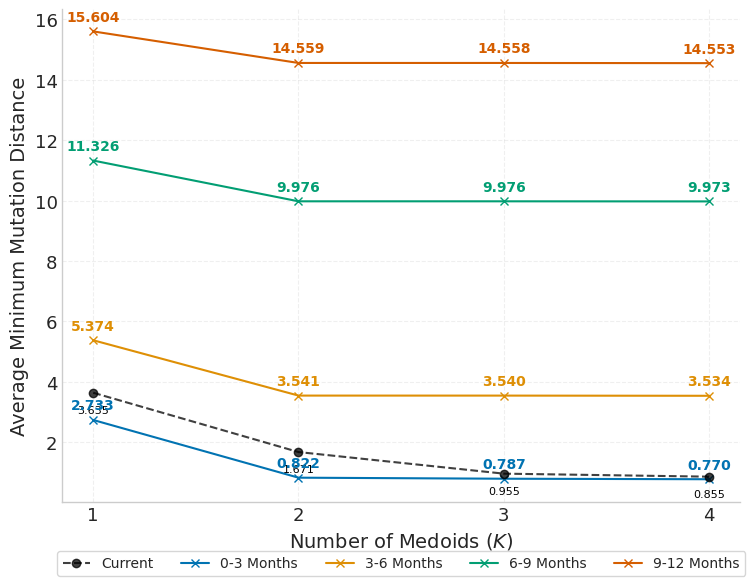

In [27]:
plot_medoid_performance(
    pam_results=pam_results,
    medoid_evaluation_results=medoid_evaluation_results,
    cutoff_date=cutoff_date
)

Score Comparisons

In [24]:
def generate_evaluation_dataframe(pam_results, medoid_evaluation_results, vaccine_results):
    """
    Constructs a DataFrame comparing specific vaccines and K-medoid sets
    across temporal intervals.
    """
    rows = []
    
    # Mapping for consistent column naming
    slice_labels = {
        "3M_1": "0-3 Months",
        "3M_2": "3-6 Months",
        "3M_3": "6-9 Months",
        "3M_4": "9-12 Months"
    }

    # 1. Process Individual Vaccines (e.g., BA.4, BA.5)
    for vaccine_id, intervals in vaccine_results.items():
        row = {"Entity": f"Vaccine: {vaccine_id}"}
        # Map internal interval keys to readable column names
        for k, v in intervals.items():
            row[slice_labels.get(k, k)] = v
        rows.append(row)

    # 2. Process K-Medoid Sets
    # Using k_values from medoid_evaluation_results to ensure alignment
    for k in sorted(medoid_evaluation_results.keys()):
        # Retrieve the specific IDs for this K
        medoid_ids = pam_results[k].get('medoids', [])
        medoid_str = ", ".join(map(str, medoid_ids))
        
        row = {"Entity": f"K={k} Medoids ({medoid_str})"}
        
        # Get evaluation distances for this K
        intervals = medoid_evaluation_results[k]
        for k_int, v_int in intervals.items():
            row[slice_labels.get(k_int, k_int)] = v_int
        rows.append(row)

    # Create DataFrame and set Entity as index (Y-axis)
    df = pd.DataFrame(rows)
    if not df.empty:
        df.set_index("Entity", inplace=True)
        
    return df

evaluation_df = generate_evaluation_dataframe(pam_results, medoid_evaluation_results, vaccine_evaluation_results)

# Display formatted table
print(evaluation_df.to_string())

                                                    0-3 Months  3-6 Months  6-9 Months  9-12 Months
Entity                                                                                             
Vaccine: XBB.1.5                                      3.569068   13.084383   26.845454    32.446927
K=1 Medoids (S_5897)                                  3.569068   13.084383   26.845454    32.446927
K=2 Medoids (S_5897, S_387141)                        3.250446   11.299837   22.695752    27.755262
K=3 Medoids (S_5897, S_387141, S_163522)              2.858369   11.133023   22.661335    27.752561
K=4 Medoids (S_5897, S_387141, S_163522, S_105676)    2.601628   11.025759   22.638511    27.749074


In [35]:
#######NEW
# Extracting strain sequences
def save_dict_to_fasta(sequence_dict, output_filename):
    """Writes a dictionary of {ID: Sequence} to a FASTA file."""
    with open(output_filename, 'w') as f:
        for seq_id, sequence in sequence_dict.items():
            f.write(f">{seq_id}\n")
            f.write(f"{sequence}\n")
            
fda_sequences = {strain: clade_to_seq[strain] for strain in recommended_strains if strain in clade_to_seq}

# --- Extraction for Selected Medoids (e.g., for K=2) ---
target_k = 2
selected_medoid_ids = pam_results[target_k]['medoids']
medoid_sequences = {m_id: id_to_seq[m_id] for m_id in selected_medoid_ids if m_id in id_to_seq}

# --- Quick Verification ---
print(f"Extracted {len(fda_sequences)} FDA sequences.")
print(f"Extracted {len(medoid_sequences)} medoid sequences for K={target_k}.")

print(medoid_sequences)
save_dict_to_fasta(medoid_sequences, "current_sequences_alpha_1.fa")

Extracted 2 FDA sequences.
Extracted 2 medoid sequences for K=2.
{'S_373': 'MFVFLVLLPLVSSQCVNLITRTQLPPAYTNSFTRGVYYPDKVFRSSVLHSTQDLFLPFFSNVTWFHAIHVSGTNGTKRFDNPVLPFNDGVYFASTEKSNIIRGWIFGTTLDSKTQSLLIVNNATNVVIKVCEFQFCNDPFLGVYYHKNNKSWMESEFRVYSSANNCTFEYVSQPFLMDLEGKQGNFKNLREFVFKNIDGYFKIYSKHTPINLGRDLPQGFSALEPLVDLPIGINITRFQTLLALHRSYLTPGDSSSGWTAGAAAYYVGYLQPRTFLLKYNENGTITDAVDCALDPLSETKCTLKSFTVEKGIYQTSNFRVQPTESIVRFPNITNLCPFDEVFNATRFASVYAWNRKRISNCVADYSVLYNFAPFFAFKCYGVSPTKLNDLCFTNVYADSFVIRGNEVSQIAPGQTGNIADYNYKLPDDFTGCVIAWNSNKLDSKVGGNYNYLYRLFRKSNLKPFERDISTEIYQAGNKPCNGVAGFNCYFPLRSYGFRPTYGVGHQPYRVVVLSFELLHAPATVCGPKKSTNLVKNKCVNFNFNGLTGTGVLTESNKKFLPFQQFGRDIADTTDAVRDPQTLEILDITPCSFGGVSVITPGTNTSNQVAVLYQGVNCTEVPVAIHADQLTPTWRVYSTGSNVFQTRAGCLIGAEYVNNSYECDIPIGAGICASYQTQTKSHRRARSVASQSIIAYTMSLGAENSVAYSNNSIAIPTNFTISVTTEILPVSMTKTSVDCTMYICGDSTECSNLLLQYGSFCTQLKRALTGIAVEQDKNTQEVFAQVKQIYKTPPIKYFGGFNFSQILPDPSKPSKRSFIEDLLFNKVTLADAGFIKQYGDCLGDIAARDLICAQKFNGLTVLPPLLTDEMIAQYTSALLAGTITSGWTFGAGAALQIPFAMQMAYRFNGIGVTQNVLYENQKLIA

Mutation Distance Comparisons

In [27]:
def calculate_and_print_vaccine_medoid_distances(recommended_strains, clade_to_seq, pam_results, id_to_seq):
    """
    Calculates Hamming distance between each vaccine and each individual medoid within each K set.
    Prints results in a hierarchical structured format.
    """
    
    # Helper for single-pair Hamming distance
    def get_hamming(s1, s2):
        if len(s1) != len(s2):
            return None
        return sum(c1 != c2 for c1, c2 in zip(s1, s2))

    print(f"{'='*60}")
    print(f"{'VACCINE VS MEDOID HAMMING DISTANCES':^60}")
    print(f"{'='*60}\n")

    for k in sorted(pam_results.keys()):
        medoid_ids = pam_results[k].get('medoids', [])
        print(f"Configuration: K = {k}")
        print(f"{'-'*30}")

        for m_id in medoid_ids:
            # Retrieve medoid sequence
            m_seq = id_to_seq.get(m_id)
            if m_seq is None:
                print(f"  [!] Medoid {m_id} not found in id_to_seq.")
                continue

            print(f"  Medoid ID: {m_id}")
            
            for vaccine_id in recommended_strains:
                # Retrieve vaccine sequence
                v_seq = clade_to_seq.get(vaccine_id)
                if v_seq is None:
                    print(f"    - vs {vaccine_id:.<15} [!] Not found in clade_to_seq")
                    continue
                
                dist = get_hamming(v_seq, m_seq)
                
                if dist is None:
                    print(f"    - vs {vaccine_id:.<15} Error: Length Mismatch")
                else:
                    print(f"    - vs {vaccine_id:.<15} Distance: {dist}")
            print() # Spacer between medoids
        print(f"{'='*60}\n")

# Usage Call:
calculate_and_print_vaccine_medoid_distances(
    recommended_strains= ['B.1'] + recommended_strains,
    clade_to_seq=clade_to_seq,
    pam_results=pam_results,
    id_to_seq=id_to_seq
)

            VACCINE VS MEDOID HAMMING DISTANCES             

Configuration: K = 1
------------------------------
  Medoid ID: S_220057
    - vs B.1............ Distance: 26
    - vs BA.4........... Distance: 2
    - vs BA.5........... Distance: 2


Configuration: K = 2
------------------------------
  Medoid ID: S_373
    - vs B.1............ Distance: 25
    - vs BA.4........... Distance: 3
    - vs BA.5........... Distance: 3

  Medoid ID: S_538
    - vs B.1............ Distance: 26
    - vs BA.4........... Distance: 0
    - vs BA.5........... Distance: 0


Configuration: K = 3
------------------------------
  Medoid ID: S_373
    - vs B.1............ Distance: 25
    - vs BA.4........... Distance: 3
    - vs BA.5........... Distance: 3

  Medoid ID: S_538
    - vs B.1............ Distance: 26
    - vs BA.4........... Distance: 0
    - vs BA.5........... Distance: 0

  Medoid ID: S_2547
    - vs B.1............ Distance: 27
    - vs BA.4........... Distance: 4
    - vs BA.5.........

PyR0 Fitness Score Comparisons

In [28]:
mutation_score_dict_pyro = (
    pyro_df.set_index("mutation")["R / R_A"].to_dict()
)

print(f"Loaded {len(mutation_score_dict_pyro)} PyR₀ mutation scores")

Loaded 2478 PyR₀ mutation scores


In [29]:
# --- Add mutation information to current sequences ---
current_seq_df = add_mutations_column(current_seq_df, id_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
current_seq_df = add_fitness_scores_pyro(current_seq_df, mutation_score_dict_pyro)

In [30]:
# --- Add mutation information to current sequences ---
vaccine_df = add_mutations_column(vaccine_df, clade_to_seq, refSeq)

# --- Compute PyR₀ fitness scores ---
vaccine_df = add_fitness_scores_pyro(vaccine_df, mutation_score_dict_pyro)

In [31]:
def print_fitness_scores(pam_results, recommended_strains, current_seq_df, vaccine_df):
    """
    Look up and print fitness_score_pyro for medoids and vaccines.
    Uses Sequence_ID as the key for lookup.
    """
    
    # Pre-index DataFrames for O(1) lookup performance
    # Handling cases where IDs might be missing
    fitness_map_medoids = current_seq_df.set_index('Sequence_ID')['Fitness_Score_pyro'].to_dict()
    fitness_map_vaccines = vaccine_df.set_index('Sequence_ID')['Fitness_Score_pyro'].to_dict()

    print(f"{'='*60}")
    print(f"{'FITNESS SCORE (PYRO) EVALUATION':^60}")
    print(f"{'='*60}\n")

    # 1. Print Vaccine Fitness Scores
    print("VACCINE STRAIN SCORES")
    print(f"{'-'*30}")
    for strain in recommended_strains:
        score = fitness_map_vaccines.get(strain, "N/A (Not Found)")
        score_val = f"{score:.5f}" if isinstance(score, float) else score
        print(f"  {strain:.<20} Score: {score_val}")
    print()

    # 2. Print Medoid Fitness Scores per K
    for k in sorted(pam_results.keys()):
        medoid_ids = pam_results[k].get('medoids', [])
        print(f"MEDOIDS FOR K = {k}")
        print(f"{'-'*30}")
        
        for m_id in medoid_ids:
            score = fitness_map_medoids.get(m_id, "N/A (Not Found)")
            score_val = f"{score:.5f}" if isinstance(score, float) else score
            print(f"  ID: {m_id:.<18} Score: {score_val}")
        print()

    print(f"{'='*60}")

print_fitness_scores(pam_results, recommended_strains, current_seq_df, vaccine_df)

              FITNESS SCORE (PYRO) EVALUATION               

VACCINE STRAIN SCORES
------------------------------
  BA.4................ Score: 4.42300
  BA.5................ Score: 4.42300

MEDOIDS FOR K = 1
------------------------------
  ID: S_220057.......... Score: 4.19998

MEDOIDS FOR K = 2
------------------------------
  ID: S_373............. Score: 4.05192
  ID: S_538............. Score: 4.42300

MEDOIDS FOR K = 3
------------------------------
  ID: S_373............. Score: 4.05192
  ID: S_538............. Score: 4.42300
  ID: S_2547............ Score: 4.08895

MEDOIDS FOR K = 4
------------------------------
  ID: S_26.............. Score: 3.53183
  ID: S_538............. Score: 4.42300
  ID: S_2547............ Score: 4.08895
  ID: S_373............. Score: 4.05192

